# Aumentar, ponderar y reducir: transformación evolutiva de atributos

**Práctica final — IA con inspiración biológica** · Máster en Ciencia y Tecnología, UC3M · Andrea López Salazar

**Resumen.** $P$ aprende con **CMA-ES**, viendo solo el entrenamiento, una transformación $X\to X'$ con **menos atributos que $X$**: corrige la forma de cada atributo (Yeo-Johnson), **aumenta** el espacio con sus componentes principales, **pondera** cada uno de los $2n$ candidatos y **conserva** los de peso $\ge\tau$, como mucho $n-1$. El umbral $\tau$ (el criterio de eliminación) también lo aprende la evolución. En 12 datasets × 5 particiones no usadas para diseñarlo, $X'$ usa el 83 % de los atributos (siempre menos de $n$) y el MAE baja en **regresión lineal** (−14,6 %, $p$ = 0,027) y **KNN** (−21,2 %); en árbol y Random Forest queda igual. Tiene el mejor rango medio frente a ocho transformaciones conocidas, y cada decisión del diseño se contrasta con una alternativa.

| Sección | Contenido |
|---|---|
| 0 | Cómo ejecutarlo |
| 1 | Qué pide el enunciado y cómo lo cumple $P$ |
| 2 | El método (código) |
| 3 | Demostración en vivo |
| 4 | Protocolo experimental |
| 5 | Experimentos |
| 6 | Resultado: ¿$e'<e$ con $\dim X'<n$? |
| 7 | Justificación de cada decisión (cribado y ablación) |
| 8 | Comparativa con otras transformaciones |
| 9 | Conclusiones y límites |

## 0. Cómo ejecutarlo

```bash
python -m venv .venv && source .venv/bin/activate        # Windows: .venv\Scripts\activate
pip install -r requirements.txt
jupyter lab notebook_final.ipynb
```

- La **primera vez** hace falta internet: diez de los doce datasets se descargan de OpenML (se guardan en `~/scikit_learn_data`). Los dos de la práctica están en `datos/`.
- Por defecto se **leen los resultados guardados** en `resultados/` y se rehace todo el análisis en segundos. Para repetir un experimento, pon su entrada de `RECALCULAR` a `True` (el CSV anterior se guarda como `.bak`).
- `N_JOBS` = procesos en paralelo. Los tiempos son con 20 procesos; con $k$, multiplícalos por $\approx 20/k$.

| Experimento | Para qué | Particiones | Tiempo (20 procesos) |
|---|---|---|---|
| `cribado` | **elegir** el diseño (fitness, parada) | exploración: semillas 0–1, 7 datasets | ≈ 25 min |
| `confirmacion` | **medir** el método final | confirmación: semillas 40–44, 12 datasets | ≈ 20 min |
| `ablacion` | **justificar** cada pieza (cambiar una cada vez) | semillas 40–41, 12 datasets | ≈ 35 min |
| `comparativa` | **comparar** con 8 transformaciones conocidas | semillas 40–44, 12 datasets | ≈ 8 min |

In [1]:
import os, sys, shutil, subprocess, inspect, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings("ignore"); pd.set_option("display.width", 200); pd.set_option("display.precision", 3)

N_JOBS = os.cpu_count()
RECALCULAR = {"cribado": False, "confirmacion": False, "ablacion": False, "comparativa": False}
import ptca, analisis as A
print(len(ptca.DATASETS), "datasets ·", N_JOBS, "procesos")

12 datasets · 22 procesos


## 1. Qué pide el enunciado y cómo lo cumple $P$

Un programa $P$ que, viendo **solo** $(X_t, y_t)$, aprenda $X \to X'$ de modo que un modelo **arbitrario** $M$ entrenado con $X'_t$ tenga menor MAE en validación ($e'<e$), empleando técnicas evolutivas para la **síntesis** de atributos y la **reducción de la dimensionalidad**.

| Requisito | Cómo se cumple | Dónde se comprueba |
|---|---|---|
| Solo con el entrenamiento | $P$ ajusta todo (forma, componentes, pesos, umbral) con $X_t$; la validación solo se usa para medir | `ptca.aprender`, `experimentos.tarea` |
| Computación evolutiva | CMA-ES busca $\theta=(\lambda, v, \tau)$ | sección 2; frente a búsqueda aleatoria y un AG en la sección 7 |
| Síntesis $z=f(x_1..x_n)$ | componentes principales del espacio con forma corregida como candidatos | sección 6 (cuántas se usan) y ablación "sin síntesis" |
| Reducción $s<n$ | como mucho $n-1$ atributos **para cualquier individuo** (en la decodificación) | sección 6: $\dim X'<n$ en todas las particiones |
| Criterio de eliminación evolutivo | CMA-ES aprende el umbral $\tau$ y los pesos: decide qué se elimina y cuánto | sección 2 |
| $e'<e$ para un $M$ arbitrario | una sola $X'$ para cuatro familias distintas (lineal, KNN, árbol, RF); fitness con tres de ellas | sección 6 |

## 2. El método

![Esquema](figuras/esquema.png)

1. **Forma**: $\tilde x_j = (\psi(x_j;\lambda_j)-\mu_j)/\sigma_j$, Yeo-Johnson con $\lambda_j\in[-2,2]$ (corrige colas y asimetrías; admite negativos).
2. **Aumentar**: $2n$ candidatos $c=[\tilde x_1..\tilde x_n \mid p_1..p_n]$, con $p$ las componentes principales de $\tilde x$ (direcciones oblicuas: lo único que puede ayudar a un árbol, que es invariante a cambios monótonos de cada atributo).
3. **Ponderar**: un peso $v_k\in[0,3]$ por candidato (para KNN, una métrica aprendida).
4. **Reducir**: se conservan los de $v_k\ge\tau$; como mucho los $n-1$ de mayor peso.

**Fitness**: media del MAE de validación cruzada (5 pliegues) de KNN, regresión lineal y un árbol, cada uno dividido por el MAE de predecir la mediana (escala común, $f=1$ es no saber nada). **Búsqueda**: CMA-ES, 1000 evaluaciones, desde "estandarizar sin componentes".

| Operador | CMA-ES |
|---|---|
| Individuo | $\theta$ real en $[0,1]^{3n+1}$, reescalado a los límites |
| Población inicial | $\mathcal N(\theta_0, 0{,}2^2 I)$; $\lambda = 4+\lfloor 3\ln D\rfloor$ individuos por generación |
| Selección | truncamiento por **rango**: los $\mu=\lambda/2$ mejores (invariante a transformaciones monótonas del fitness; robusta al ruido) |
| Recombinación | intermedia ponderada de los $\mu$ seleccionados (promedia el ruido de la validación cruzada) |
| Mutación | $\mathcal N(m,\sigma^2C)$; $\sigma$ y $C$ adaptativas: aprende qué genes se mueven juntos |
| Reemplazo | $(\mu/\mu_w,\lambda)$ generacional; se guarda el mejor evaluado |
| Restricciones | cubo $[0,1]^D$; $\dim X'<n$ por decodificación |
| Parada | 1000 evaluaciones |

In [2]:
print(inspect.getsource(ptca.Transformacion.fit))
print(inspect.getsource(ptca.hacer_fitness))

    def fit(self, Xt):
        n, th, k = self.n, self.theta, (2 if self.componentes else 1) * self.n
        self.lam, self.v, self.tau = th[:n], th[n:n + k], float(th[n + k])
        T = yeo_johnson(Xt, self.lam)
        self.mu, self.sd = T.mean(0), T.std(0)
        self.sd[self.sd == 0] = 1.0
        C = (T - self.mu) / self.sd
        self.V = np.linalg.svd(C, full_matrices=False)[2].T          # componentes del espacio con forma
        self.psd = (C @ self.V).std(0)
        self.psd[self.psd < 1e-12] = 1.0
        S = np.where(self.v >= self.tau)[0]
        if self.limite and len(S) >= n:                              # reducción: como mucho n − 1
            S = np.sort(S[np.argsort(-self.v[S])[:n - 1]])
        if len(S) == 0:
            S = np.array([np.argmax(self.v)])
        self.S = S
        return self

def hacer_fitness(Xs, ys, semilla, fitness=FITNESS_FINAL, agregacion="media", **opciones):
    """f(θ) que minimiza la búsqueda. agregacion='media' (método) o 'minimax' 

## 3. Demostración en vivo

$P$ en una partición de california (300 evaluaciones para que sea rápido; el método usa 1000).

n = 8 -> dim X' = 7 (4 originales + 3 componentes), τ = 0.02, 45 s


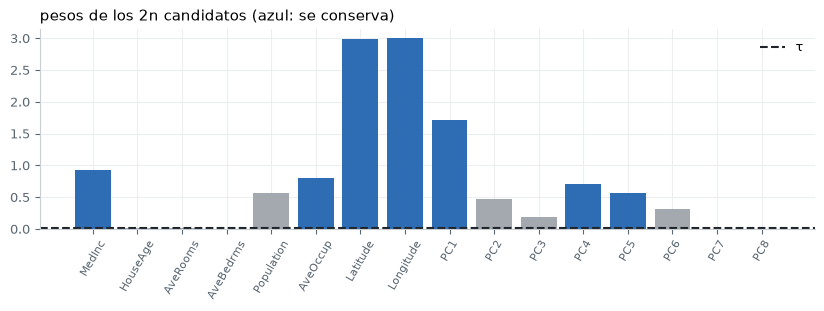

,e,e',cambio
modelo,,,
Regresión lineal,0.542,0.515,-5.1 %
KNN,0.834,0.341,-59.0 %
Árbol,0.477,0.445,-6.7 %
Random Forest,0.342,0.326,-4.6 %


In [3]:
Xt, Xv, yt, yv = ptca.particion("california", 40)
t0 = time.time()
P = ptca.aprender(Xt, yt, 40, presupuesto=300)                      # <- solo entrenamiento
print(f"n = {Xt.shape[1]} -> dim X' = {P.dim} ({P.n_orig} originales + {P.n_comp} componentes), τ = {P.tau:.2f}, {time.time()-t0:.0f} s")
filas = []
for m, mod in ptca.modelos(40).items():
    e = np.mean(np.abs(mod.fit(Xt, yt).predict(Xv) - yv))
    e2 = np.mean(np.abs(mod.fit(P.transform(Xt), yt).predict(P.transform(Xv)) - yv))
    filas.append(dict(modelo=m, e=e, **{"e'": e2, "cambio": f"{100*(e2/e-1):+.1f} %"}))
cols = list(pd.read_csv("datos/California.csv").columns.drop("MedHouseVal"))
etiq = cols + [f"PC{i+1}" for i in range(len(cols))]
fig, ax = plt.subplots(figsize=(10, 2.6))
dentro = np.isin(np.arange(2 * len(cols)), P.S)
ax.bar(range(len(etiq)), P.v, color=np.where(dentro, A.AZUL, A.GRIS)); ax.axhline(P.tau, color=A.TINTA, ls="--", label="τ")
ax.set_xticks(range(len(etiq)), etiq, rotation=60, fontsize=8); ax.legend(); ax.set_title("pesos de los 2n candidatos (azul: se conserva)", loc="left")
plt.show(); pd.DataFrame(filas).set_index("modelo")

## 4. Protocolo experimental

- **12 datasets** de regresión: los 2 de la práctica y 10 de OpenML (6–12 atributos; ≤ 10 000 filas).
- **Diseño en dos fases**: las decisiones se toman en un **cribado** con semillas de *exploración* (0–1); el método elegido se mide en particiones 70/30 **nuevas** (semillas 40–44). Así el resultado final no está ajustado a las particiones con las que se mide.
- **Modelos triviales y fijos**: regresión lineal, KNN ($k=5$), árbol de decisión y Random Forest (100 árboles), con parámetros por defecto. El enunciado fija $M$: ajustarlo sería cambiar el modelo, no los datos.
- **Estadística por dataset**: las particiones de un dataset comparten filas, así que la unidad es el dataset ($n=12$). Cada dataset se resume con la media geométrica de $e'/e$; pares con **Wilcoxon** y corrección de **Holm**; comparaciones múltiples con **Friedman** y **Nemenyi** (Demšar, 2006).
- **Ningún dataset se excluye** a posteriori; el único caso negativo (kin8nm) se analiza aparte.

## 5. Experimentos

In [4]:
def ejecutar(nombre):
    csv = os.path.join("resultados", nombre + ".csv")
    if not RECALCULAR[nombre]:
        print(f"[{nombre}] resultados guardados: {csv}" if os.path.exists(csv) else f"[{nombre}] FALTA {csv}"); return
    if os.path.exists(csv):
        shutil.copy(csv, csv + ".bak"); os.remove(csv)
    t0 = time.time()
    r = subprocess.run([sys.executable, "experimentos.py", nombre], env=dict(os.environ, N_JOBS=str(N_JOBS)),
                       capture_output=True, text=True)
    print(f"[{nombre}] {(time.time()-t0)/60:.1f} min", r.stderr[-1500:] if r.returncode else "")

for nombre in ["cribado", "confirmacion", "ablacion", "comparativa"]:
    ejecutar(nombre)
cifras = A.todas()                       # figuras/, numeros.tex y tablas.tex (memoria, paper y póster)
print(len(cifras), "cifras exportadas")

[cribado] resultados guardados: resultados/cribado.csv
[confirmacion] resultados guardados: resultados/confirmacion.csv
[ablacion] resultados guardados: resultados/ablacion.csv
[comparativa] resultados guardados: resultados/comparativa.csv


148 cifras exportadas


## 6. Resultado: ¿$e'<e$ con $\dim X'<n$?

Confirmación: 12 datasets × 5 particiones nuevas. $e'/e$ (media geométrica), datasets en los que mejora y $p$ de Wilcoxon por dataset con Holm, frente a $X$ original y frente a $X$ estandarizado.

,estándar,P (e'/e),datasets e'<e,p Holm,% vs estándar,p Holm vs estándar,peor dataset,e'/e peor
Regresión lineal,0.982,0.854,11,0.027,-13.083,0.027,kin8nm,1.012
KNN,0.876,0.788,9,0.161,-10.012,0.386,kin8nm,1.285
Árbol,1.000,0.994,5,1.000,-0.662,1.000,kin8nm,1.067
Random Forest,1.000,1.003,5,1.000,0.293,1.000,kin8nm,1.124


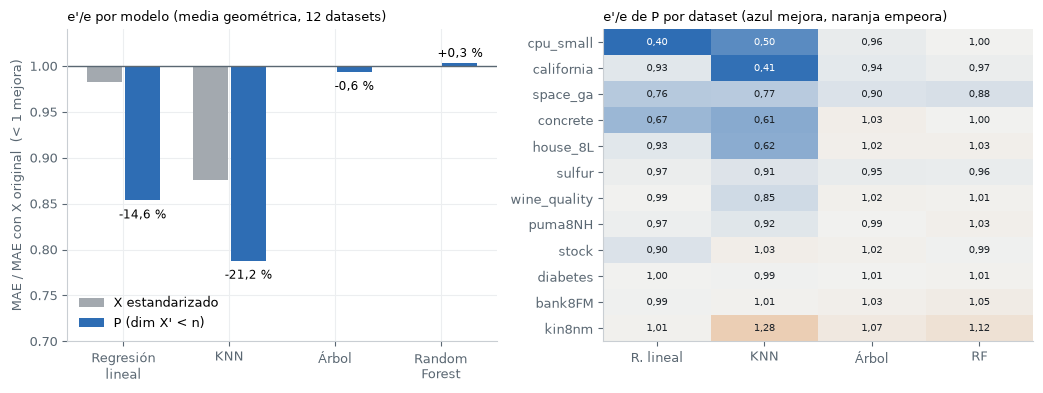

In [5]:
t = A.tabla_principal()
display(t[["estándar", "cociente", "ds_mejora", "p_holm", "vs_est", "p_est_holm", "peor_ds", "peor"]].rename(columns={
    "cociente": "P (e'/e)", "ds_mejora": "datasets e'<e", "p_holm": "p Holm", "vs_est": "% vs estándar",
    "p_est_holm": "p Holm vs estándar", "peor_ds": "peor dataset", "peor": "e'/e peor"}))
A.fig_principal(); plt.show()

**Lectura.** Con menos atributos que $X$, $P$ reduce el MAE de la **regresión lineal** un −14,6 % (mejora en 11/12 datasets; $p$ con Holm = 0,027) y el de **KNN** un −21,2 % (9/12 datasets). También mejora a estandarizar: RL −13,1 % ($p$ = 0,027) y KNN −10,0 %. Las mayores reducciones son −59,6 % en cpu_small (RL; el MAE pasa de 6,25 a 2,52) y −58,7 % en california (KNN).

En el **árbol** (−0,6 %) y en **RF** (+0,3 %) el error queda igual: un árbol no cambia con la forma ni con los pesos de un atributo, y con menos de $n$ atributos solo puede ganar si alguna dirección oblicua es mejor corte que el atributo original al que sustituye.

KNN no es significativo tras Holm ($p$ sin corregir = 0,027) por un único dataset, **kin8nm** (+28,5 %): sus atributos importan todos por igual y reducir obliga a perder información.

In [6]:
display(Markdown("**Sensibilidad: sin kin8nm** (no es una selección: se informa del resultado con los 12)"))
display(A.tabla_sensibilidad()[["cambio", "ds_mejora", "ds", "p_holm"]])
td, u = A.tabla_dimension()
display(Markdown("**Reducción y síntesis por dataset** (media de 5 particiones)")); display(td.round(2))
print(f"dim X' < n en todas las particiones: {bool((u.dim < u.n).all())} · dim X'/n medio {(u.dim/u.n).mean():.2f} · "
      f"componentes en el {(u.n_comp > 0).mean():.0%} de las particiones · búsqueda: mediana {u.segundos.median():.0f} s")

**Sensibilidad: sin kin8nm** (no es una selección: se informa del resultado con los 12)

,cambio,ds_mejora,ds,p_holm
Regresión lineal,-15.945,11,11,0.004
KNN,-24.627,9,11,0.021
Árbol,-1.273,5,11,1.000
Random Forest,-0.761,5,11,1.000


**Reducción y síntesis por dataset** (media de 5 particiones)

,n,orig,comp,dim
dataset,,,,
diabetes,10,6.2,2.8,9.0
california,8,5.0,2.0,7.0
concrete_compressive_strength,8,5.8,1.0,6.8
stock,9,6.4,1.6,8.0
space_ga,6,2.8,2.2,5.0
sulfur,6,3.0,2.0,5.0
kin8nm,8,4.6,2.4,7.0
bank8FM,8,3.6,3.4,7.0
puma8NH,8,2.2,0.6,2.8


dim X' < n en todas las particiones: True · dim X'/n medio 0.83 · componentes en el 93% de las particiones · búsqueda: mediana 292 s


**Lectura.** Sin kin8nm (análisis de sensibilidad; el resultado que cuenta es el de los 12) KNN mejora −24,6 % ($p$ = 0,021) y la media de los cuatro modelos pasa de −9,5 % a −11,2 %.

$\dim X'<n$ en **todas** las particiones: $X'$ usa de media el 83 % de $n$, con 4,9 atributos originales y 2,2 componentes. La evolución elimina el 43 % de los atributos originales y conserva componentes en el 93 % de las particiones: **síntesis y reducción ocurren a la vez**, y qué se elimina lo deciden los pesos y el umbral $\tau$ que aprende CMA-ES. Cada búsqueda tarda una mediana de 292 s (máximo 438 s).

## 7. Justificación de cada decisión

### 7.1 Cribado de diseño (semillas de exploración)
Cada fila cambia **cómo se evalúa** a los candidatos (fitness) o **cuándo se para**. "Un fitness por familia" da a cada modelo la $X'$ aprendida con su propio fitness (cuatro $X'$ distintas).

14 particiones de exploración


modelo,Regresión lineal,KNN,Árbol,Random Forest,media,peor,segundos,evaluaciones
representacion,,,,,,,,
P,0.907,0.758,0.961,0.993,0.900,0.993,199.020,1002.000
fitness solo KNN,0.963,0.740,0.967,0.992,0.909,0.992,113.169,1002.000
fitness minimax,0.942,0.824,0.990,1.012,0.939,1.012,233.815,1002.000
familia,0.897,0.740,0.957,1.002,0.893,1.002,121.316,1000.000
parada (paciencia 15),0.911,0.794,0.998,1.028,0.928,1.028,69.350,378.281
parada (paciencia 30),0.907,0.794,0.987,1.022,0.923,1.022,84.138,678.496
elegir θ con apartado,0.906,0.795,0.988,1.021,0.923,1.021,94.983,859.090


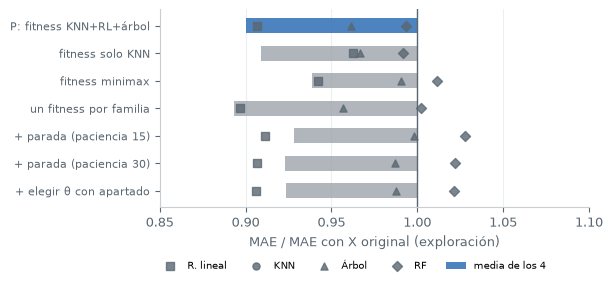

In [7]:
gc, ncr = A.tabla_cribado(); print(ncr, "particiones de exploración"); display(gc.round(3))
A.fig_barras_tabla(gc, A.MODELOS, A.ET_CRIB, "P", "MAE / MAE con X original (exploración)"); plt.show()

**Lectura.** *Fitness*: con solo KNN, la $X'$ sirve sobre todo a KNN (0,740); con tres familias, la media de los cuatro modelos mejora (0,900 frente a 0,909). Exigir que mejoren todos a la vez (**minimax**: el peor modelo, cada uno relativo a sí mismo) empeora (0,939): el máximo de cuatro estimaciones ruidosas premia el ruido. **Una $X'$ por familia** apenas mejora (0,893) y deja de ser una sola $X'$ para un $M$ arbitrario, que es lo que pide el enunciado.

*Parada*: apartar un 20 % del entrenamiento para parar ante el sobreajuste ahorra tiempo (69 s frente a 199 s), pero empeora (0,928; 0,923 con más paciencia; 0,923 usando lo apartado solo para elegir $\theta$): quita datos al fitness a cambio de un criterio demasiado ruidoso. Por eso $P$ usa el fitness de tres familias y un presupuesto fijo de 1000 evaluaciones.

### 7.2 Ablación (particiones de confirmación)
Se cambia **una sola pieza** de $P$ cada vez. Cociente frente a $P$ (> 1: peor que $P$); $^*$ en la memoria: $p<0{,}05$ por dataset con Holm.

In [8]:
ta, nab = A.tabla_ablacion(); print(nab, "particiones"); display(ta.round(3))

24 particiones


,Regresión lineal,p Regresión lineal,KNN,p KNN,Árbol,p Árbol,Random Forest,p Random Forest,media,dim/n,segundos
fitness solo KNN,1.122,0.010,0.968,0.171,0.979,0.313,0.995,1.000,1.014,0.826,203.960
sin síntesis,1.002,0.761,0.986,1.000,1.005,1.000,1.001,1.000,0.998,0.770,310.194
sin forma (λ = 1),1.141,0.007,1.022,0.611,1.000,1.000,1.006,1.000,1.041,0.751,324.082
sin límite n−1,1.004,0.761,0.987,1.000,0.989,1.000,0.994,1.000,0.994,1.316,410.698
búsqueda aleatoria,1.045,0.003,1.055,0.161,1.019,1.000,1.021,0.384,1.035,0.820,311.623
algoritmo genético,1.003,0.700,1.007,0.518,0.998,1.000,0.993,1.000,1.000,0.848,249.295


**Lectura** (24 particiones; cambio frente a $P$, > 0 es peor que $P$):

- **Forma** — la pieza que más aporta: sin ella ($\lambda=1$) RL empeora +14,1 % (significativo).
- **Fitness de tres familias** — con solo KNN, KNN gana −3,2 % pero RL pierde +12,2 % (significativo): una sola $X'$ para un $M$ arbitrario necesita varias familias en el fitness.
- **Búsqueda evolutiva** — con el mismo presupuesto (1000 evaluaciones), la búsqueda aleatoria empeora los cuatro modelos (+3,5 % de media; RL +4,5 %, significativo).
- **CMA-ES frente a un AG** — empate (+0,0 %): cuenta buscar con selección y variación más que el algoritmo concreto. Se prefiere CMA-ES porque adapta sola la mutación, sin tasas de cruce y mutación que fijar a mano.
- **Límite de $n-1$** — sin él el error no cambia de forma apreciable (−0,6 %), pero $X'$ crece hasta 1,32·$n$: el límite garantiza la reducción que pide el enunciado sin coste medible.
- **Síntesis** — sin ella el error tampoco cambia (−0,2 %). Las componentes no dan una mejora medible en estos datos, aunque la evolución las conserva en el 93 % de las particiones; se mantienen porque el enunciado pide síntesis y no empeoran nada.

## 8. Comparativa con otras transformaciones

Mismas particiones: estandarizar, Yeo-Johnson por máxima verosimilitud, cuantiles, "solo PCA" (95 % de varianza o % por validación cruzada), $X$ estandarizado + su PCA, MLKR (aprendizaje de métricas) y programación genética (`gplearn`). Rango medio de Friedman sobre los cuatro modelos y $\dim X'/n$.

,Regresión lineal,KNN,Árbol,Random Forest,rango,dim/n,p Regresión lineal,p KNN,p Árbol,p Random Forest
P,0.854,0.788,0.994,1.003,3.562,0.832,NaN,NaN,NaN,NaN
PG (gplearn),0.843,0.820,1.007,1.008,4.031,2.000,0.677,0.939,1.000,1.000
estándar + PCA,0.982,0.876,0.994,0.981,4.073,2.000,0.024,0.386,1.000,1.000
YJ máx. verosimilitud,1.024,0.855,1.015,1.017,4.333,1.000,0.032,0.529,1.000,1.000
estándar,0.982,0.876,1.000,1.000,4.594,1.000,0.024,0.386,1.000,1.000
MLKR,0.982,0.775,1.020,1.026,5.156,1.000,0.024,0.939,1.000,0.776
cuantiles,1.081,0.882,1.001,1.000,5.500,1.000,0.004,0.215,1.000,1.000
PCA v-CV,0.990,0.880,1.187,1.151,6.594,0.905,0.024,0.239,0.027,0.098
PCA 95 %,1.006,0.896,1.193,1.179,7.156,0.794,0.024,0.239,0.027,0.098


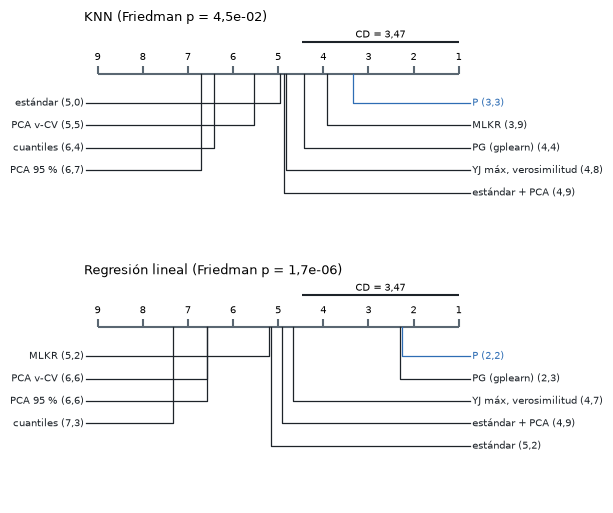

In [9]:
tc = A.tabla_comparativa()
display(tc[A.MODELOS + ["rango", "dim/n"] + ["p " + m for m in A.MODELOS]].sort_values("rango").round(3))
A.fig_cd(); plt.show()

**Lectura.** $P$ tiene el **mejor rango medio** de Friedman (3,6) entre nueve transformaciones, por delante de la programación genética (4,0), de $X$ estandarizado + su PCA (4,1) y de Yeo-Johnson por máxima verosimilitud (4,3). Es la única que mejora a la vez RL y KNN **reduciendo** la dimensión:

- la programación genética empata en RL (−15,7 %) pero usa $2n$ atributos;
- MLKR, que aprende una métrica para KNN, es la mejor en KNN (−22,5 %) pero apenas ayuda a RL (−1,8 %);
- "solo PCA", la otra forma de reducir, empeora a RF un +17,9 %: sustituir los ejes originales daña a los árboles; *elegir* cuáles conservar, no.

## 9. Conclusiones y límites

- **$P$ cumple todos los requisitos**: solo entrenamiento, búsqueda evolutiva, síntesis y reducción ($\dim X'<n$ siempre, 83 % de $n$ de media) con un criterio de eliminación que aprende CMA-ES.
- **$e'<e$ en regresión lineal** (−14,6 %, significativo) **y KNN** (−21,2 %), con reducciones de hasta −59,6 % y −58,7 %; en los árboles el error queda igual.
- **Mejor rango medio** entre nueve transformaciones, y la única que mejora RL y KNN a la vez reduciendo la dimensión.
- **Cada decisión está contrastada**: la forma, el fitness de tres familias y la búsqueda evolutiva son necesarias; el límite de $n-1$ garantiza la reducción sin coste; la parada por sobreajuste se probó y se descartó.
- **Límites**:
  - 12 datasets pequeños y numéricos, con un caso negativo (kin8nm).
  - La síntesis cumple el requisito pero no reduce el error de forma medible, y un AG rinde igual que CMA-ES.
  - Los árboles no mejoran porque lo que les ayuda es *añadir* dimensiones, que el enunciado no permite.
  - Cada búsqueda tarda unos 292 s.